# Esercizi da soli · La regressione logistica

*Metodi Matematici e Statistici per le Decisioni Economiche · A.A. 2026/27 · Esercitazione 3*

**Versione svolta**, con il codice e i commenti per leggere i risultati. Prima prova da solo con `esercitazione3_da_soli_bank.ipynb`, senza soluzioni.

Una banca telefona ai suoi clienti per proporre un **deposito a termine** (un conto in cui il cliente lascia i soldi fermi per un certo tempo, in cambio di un interesse). Vuole capire **chi lo sottoscriverà**, per chiamare le persone giuste. È il LAB Bank della lezione 3: `bank.csv`, 4.521 clienti.

Le colonne che usiamo:
- `y` (la y): **1** se il cliente ha **sottoscritto** il deposito, **0** se no. Il **sì** è "sottoscrive";
- `duration`: quanto è durata l'ultima telefonata della banca al cliente, in **secondi**;
- `housing`: `yes` se il cliente ha un **mutuo** sulla casa, `no` se no;
- `loan`: `yes` se il cliente ha un **prestito personale**, `no` se no;
- `age`: l'età del cliente, in anni.

Le altre colonne oggi non servono.

**La cosa più importante è capire che cosa significano le variabili**, per interpretare correttamente i risultati: il sì (1) è il cliente che **sottoscrive** il deposito; la durata è in **secondi**, non in minuti; `housing` e `loan` dicono se il cliente ha **già un debito** con una banca.

Gli esercizi seguono gli stessi passi di quelli fatti insieme sui clienti della carta di credito. **Prima di scrivere codice, leggi la domanda** e completa la riga **Cosa mi chiede?**:
- la **y**: cosa vogliamo spiegare o prevedere;
- la **x**: con cosa la spieghiamo;
- il **comando**: un modello, una previsione, un grafico...

Dopo il codice, nella cella **Risposta**, scrivi **a parole** cosa vuol dire il risultato per la banca.

> **Per salvare il tuo lavoro scarica il notebook:** File → Scarica → Scarica .ipynb. Il file scaricato è tuo: per riaprirlo, su Colab File → Carica notebook, e da lì Salva funziona normalmente. Se hai aperto il notebook dal sito con *Apri in Colab*, non usare Salva: Colab proverebbe a salvarlo su GitHub.

In [ ]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf
import math
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
bank = pl.read_csv("https://www.vincnardelli.com/msd/dati/bank.csv")
bank.head()

age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
i64,str,str,str,str,i64,str,str,str,i64,str,i64,i64,i64,i64,str,i64
30,"""unemployed""","""married""","""primary""","""no""",1787,"""no""","""no""","""cellular""",19,"""oct""",79,1,-1,0,"""unknown""",0
33,"""services""","""married""","""secondary""","""no""",4789,"""yes""","""yes""","""cellular""",11,"""may""",220,1,339,4,"""failure""",0
35,"""management""","""single""","""tertiary""","""no""",1350,"""yes""","""no""","""cellular""",16,"""apr""",185,1,330,1,"""failure""",0
30,"""management""","""married""","""tertiary""","""no""",1476,"""yes""","""yes""","""unknown""",3,"""jun""",199,4,-1,0,"""unknown""",0
59,"""blue-collar""","""married""","""secondary""","""no""",0,"""yes""","""no""","""unknown""",5,"""may""",226,1,-1,0,"""unknown""",0


## Parte 1 · La regressione logistica

### 3.1 Quanti clienti hanno sottoscritto il deposito? Le loro telefonate sono state più lunghe?

**Cosa mi chiede?** Contare i clienti con `y` uguale a 1: `filter`. Confrontare la durata nei due gruppi: un boxplot.

In [ ]:
# 521 clienti su 4.521 hanno sottoscritto (circa l'11,5%)
bank.filter(pl.col("y") == 1)

age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
i64,str,str,str,str,i64,str,str,str,i64,str,i64,i64,i64,i64,str,i64
20,"""student""","""single""","""secondary""","""no""",502,"""no""","""no""","""cellular""",30,"""apr""",261,1,-1,0,"""unknown""",1
68,"""retired""","""divorced""","""secondary""","""no""",4189,"""no""","""no""","""telephone""",14,"""jul""",897,2,-1,0,"""unknown""",1
32,"""management""","""single""","""tertiary""","""no""",2536,"""yes""","""no""","""cellular""",26,"""aug""",958,6,-1,0,"""unknown""",1
49,"""technician""","""married""","""tertiary""","""no""",1235,"""no""","""no""","""cellular""",13,"""aug""",354,3,-1,0,"""unknown""",1
78,"""retired""","""divorced""","""primary""","""no""",229,"""no""","""no""","""telephone""",22,"""oct""",97,1,-1,0,"""unknown""",1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
26,"""technician""","""single""","""secondary""","""no""",668,"""yes""","""no""","""unknown""",28,"""may""",576,3,-1,0,"""unknown""",1
60,"""self-employed""","""married""","""primary""","""no""",362,"""no""","""yes""","""cellular""",29,"""jul""",816,6,-1,0,"""unknown""",1
42,"""blue-collar""","""single""","""secondary""","""no""",1080,"""yes""","""yes""","""cellular""",13,"""may""",951,3,370,4,"""failure""",1


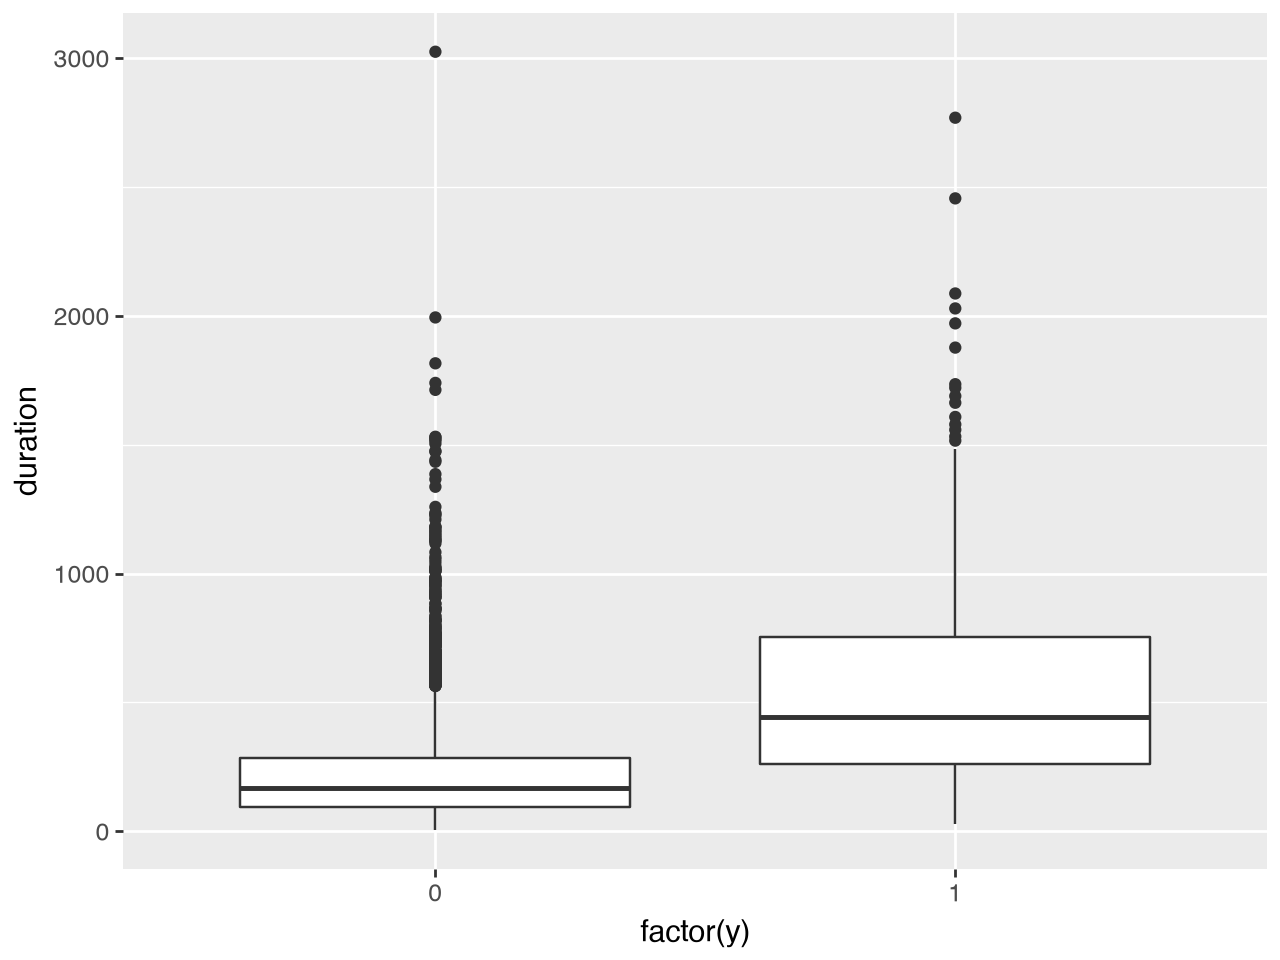

In [ ]:
# sulle x i due gruppi (0 non sottoscrive, 1 sottoscrive), sulle y la variabile numerica che confrontiamo, la durata
# factor(y): y è un numero (0/1), factor lo usa come due gruppi, non come un numero su un asse
ggplot(bank, aes(x="factor(y)", y="duration")) + geom_boxplot()

**Risposta.**
- **521 clienti su 4.521** hanno sottoscritto, circa l'11,5%: la grande maggioranza dice no;
- chi sottoscrive ha avuto **telefonate più lunghe**: in media 553 secondi, contro 226. Ci aspettiamo che più è lunga la telefonata, più sia probabile il sì.

### 3.2 Stima la regressione logistica di `y` in funzione di `duration` e disegna la curva.

**Cosa mi chiede?** y = `y`, sottoscrive sì o no: è **binaria** (1 sottoscrive, 0 no). x = `duration`. Comando: `smf.logit`. Poi la curva: la colonna `prob` con la probabilità di ogni cliente, i punti, la curva.

In [ ]:
# la y è 0/1: al posto di ols si usa logit
modello = smf.logit("y ~ duration", data=bank).fit()

Optimization terminated successfully.
         Current function value: 0.298800
         Iterations 7


In [ ]:
# prob: una colonna nuova con la probabilità di sottoscrivere che il modello dà a ogni cliente
bank = bank.with_columns(prob=modello.predict())
bank.head()

age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,prob
i64,str,str,str,str,i64,str,str,str,i64,str,i64,i64,i64,i64,str,i64,f64
30,"""unemployed""","""married""","""primary""","""no""",1787,"""no""","""no""","""cellular""",19,"""oct""",79,1,-1,0,"""unknown""",0,0.048544
33,"""services""","""married""","""secondary""","""no""",4789,"""yes""","""yes""","""cellular""",11,"""may""",220,1,339,4,"""failure""",0,0.077627
35,"""management""","""single""","""tertiary""","""no""",1350,"""yes""","""no""","""cellular""",16,"""apr""",185,1,330,1,"""failure""",0,0.069186
30,"""management""","""married""","""tertiary""","""no""",1476,"""yes""","""yes""","""unknown""",3,"""jun""",199,4,-1,0,"""unknown""",0,0.072455
59,"""blue-collar""","""married""","""secondary""","""no""",0,"""yes""","""no""","""unknown""",5,"""may""",226,1,-1,0,"""unknown""",0,0.079166


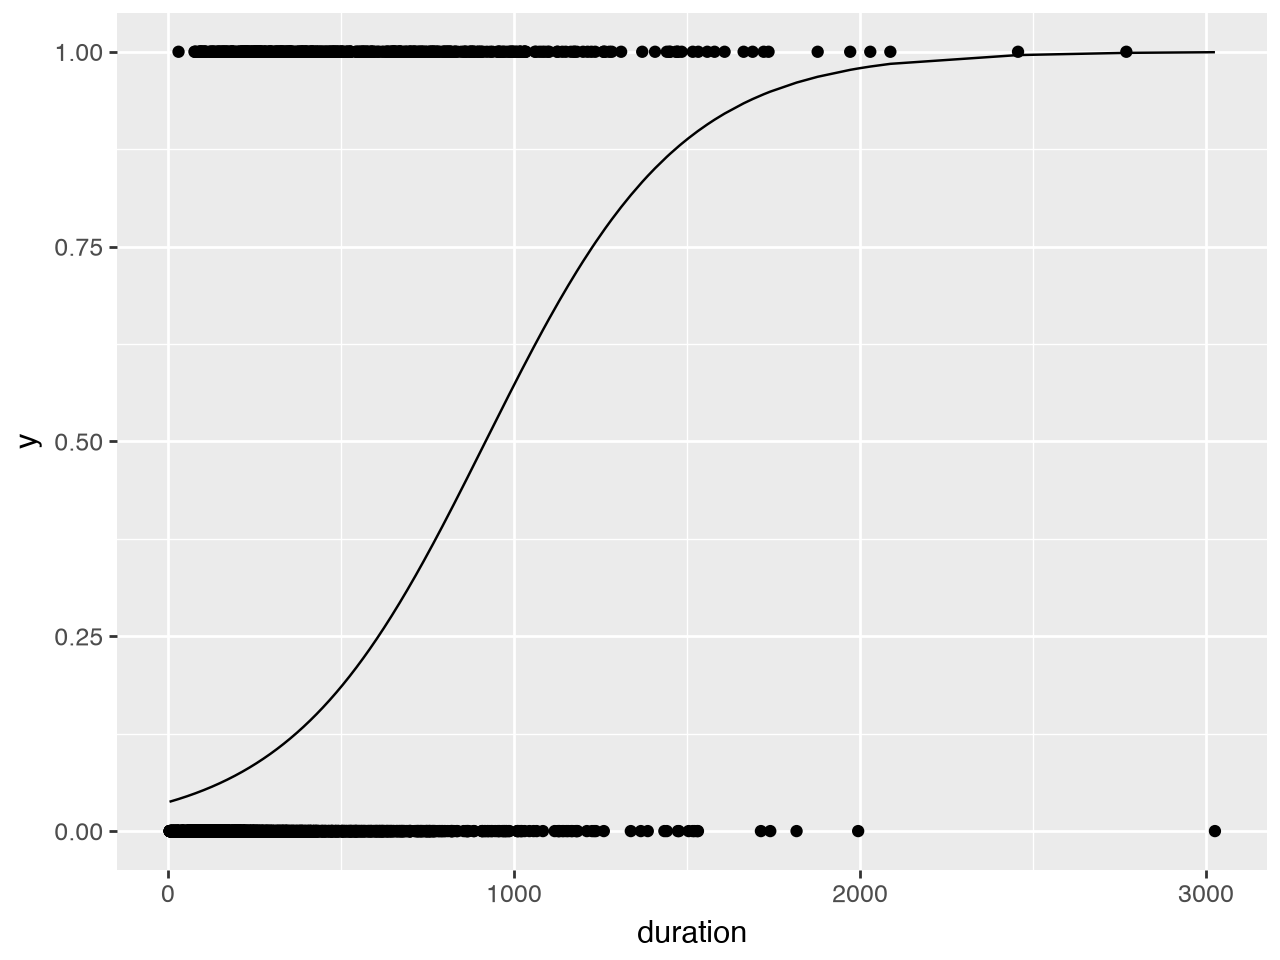

In [ ]:
# i punti sono la realtà (0 o 1); la curva è la colonna prob: per questo nella curva la y è "prob"
(ggplot(bank, aes(x="duration", y="y")) + geom_point()
    + geom_line(aes(y="prob")))

**Risposta.**
- la curva resta **sempre tra 0 e 1**: è una probabilità;
- **sale con la durata**: più lunga la telefonata, più è probabile che il cliente sottoscriva.

### 3.3 La durata è significativa? In che direzione? Ha senso interpretare l'intercetta?

**Cosa mi chiede?** Leggere il `summary`: i coefficienti sono log-odds, si legge il segno. Poi il p-value e lo Pseudo R².

In [ ]:
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      y   No. Observations:                 4521
Model:                          Logit   Df Residuals:                     4519
Method:                           MLE   Df Model:                            1
Date:                Thu, 26 Nov 2026   Pseudo R-squ.:                  0.1638
Time:                        15:31:32   Log-Likelihood:                -1350.9
converged:                       True   LL-Null:                       -1615.5
Covariance Type:            nonrobust   LLR p-value:                4.118e-117
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.2559      0.085    -38.497      0.000      -3.422      -3.090
duration       0.0035      0.000     20.714      0.000       0.003       0.004
==============================================================================
"""

**Risposta.** I coefficienti sono log-odds: si legge il segno.
- **`duration`** (β₁) +0.0035: segno **positivo**, più lunga la telefonata, più è probabile che il cliente sottoscriva;
- **p-value** 0.000 < 0.05: `duration` è **significativa**;
- **Pseudo R-squ.** 0.16: come l'R², va da 0 a 1;
- **intercetta** (β₀) −3.26: sarebbe una telefonata di 0 secondi, che non esiste: **non si interpreta** (con il saldo 0 dei clienti della carta, invece, aveva senso).

### 3.4 Con che probabilità sottoscrive un cliente con una telefonata di 300 secondi (5 minuti)? E uno con 360 secondi, cioè un minuto in più? Scrivi gli odds come "… a 100" e la probabilità come "… su …".

**Cosa mi chiede?** I tre passi: i log-odds con `predict(..., which="linear")`, gli odds con `math.e` elevato ai log-odds, la probabilità con `predict`.

In [ ]:
# due clienti: un minuto (60 secondi) di telefonata di differenza
nuovi = {"duration": [300, 360]}

In [ ]:
# nel risultato, 0 e 1 a sinistra non sono la y: sono la posizione dei valori che abbiamo dato a duration in nuovi
# in Python si conta da 0: 0 = il primo valore (300 secondi), 1 = il secondo (360 secondi)
# log-odds: la retta beta0 + beta1 * duration
# -3.26 + 0.00355 * 300 = -2.19 e -3.26 + 0.00355 * 360 = -1.98: negativi, è meno probabile che sottoscrivano
modello.predict(nuovi, which="linear")

0   -2.191069
1   -1.978096
dtype: float64

In [ ]:
# odds: e elevato alla retta (ai log-odds)
# e^(-2.19) = 0.11: "11 a 100"; e^(-1.98) = 0.14: "14 a 100"
math.e ** modello.predict(nuovi, which="linear")

0    0.111797
1    0.138332
dtype: float64

In [ ]:
# probabilità: odds / (1 + odds); predict da solo fa tutti e tre i passi
# 0.11 / (1 + 0.11) = 0.10 e 0.14 / (1 + 0.14) = 0.12
modello.predict(nuovi)

0    0.100555
1    0.121522
dtype: float64

**Risposta.**

| | log-odds | odds | probabilità |
|---|---|---|---|
| **300 secondi** | −2.19: meno probabile che sottoscriva | 0.11: "11 a 100", su 100 che non sottoscrivono, 11 sottoscrivono | 0.10: 11 su 111 |
| **360 secondi** | −1.98: meno probabile che sottoscriva | 0.14: "14 a 100" | 0.12: 14 su 114 |

### 3.5 Di quanto cambiano gli odds di sottoscrivere con un minuto in più di telefonata? E con 5 minuti in più? Aumenta della stessa percentuale anche la probabilità?

**Cosa mi chiede?** L'odds ratio: `math.e` elevato al coefficiente, per un secondo; per un minuto a 60 volte il coefficiente, per 5 minuti a 300 volte.

In [ ]:
# l'odds ratio è la variazione percentuale degli odds del sì (sottoscrivere) quando la x sale
# si usa solo il coefficiente beta1, moltiplicato per quanto sale la x: e^(beta1 * dx)
# duration 1.0036: ogni secondo in più, gli odds di sottoscrivere si moltiplicano per 1.0036 (+0.36%)
# (Intercept non è un odds ratio: sarebbero gli odds con una telefonata di 0 secondi)
math.e ** modello.params

Intercept    0.038545
duration     1.003556
dtype: float64

In [ ]:
# un minuto in più: e^(0.00355 * 60) = 1.24
math.e ** (60 * modello.params["duration"])

np.float64(1.2373514568856292)

In [ ]:
# 5 minuti in più: e^(0.00355 * 300) = 2.90
math.e ** (300 * modello.params["duration"])

np.float64(2.9004499121513043)

**Risposta.** L'odds ratio dice per quanto si **moltiplicano** gli odds di sottoscrivere:
- **1 secondo** in più: × 1.0036, gli odds aumentano dello **0.36%**;
- **1 minuto** in più: × 1.24, gli odds aumentano del **24%**. Controprova con i due clienti dell'esercizio 3.4, a un minuto di distanza: 0.138 / 0.112 = 1.24;
- **5 minuti** in più: × 2.90, gli odds aumentano del **190%**, quasi triplicano. Non è 5 × 24% = 120%: ogni minuto moltiplica per 1.24, cinque volte di fila (1.24 × 1.24 × 1.24 × 1.24 × 1.24 = 2.90).

Attenzione: aumentano gli **odds**, non la probabilità. Con un minuto in più la probabilità passa da 0.10 a 0.12: sale di 2 punti, non del 24%.

## Parte 2 · Scegliere fra due modelli: semplice o multipla?

### 3.6 Aggiungi `housing`, `loan` e `age`. Quali variabili sono significative? Chi ha un mutuo o un prestito sottoscrive di più o di meno? Lo Pseudo R² sale?

**Cosa mi chiede?** Una logistica multipla: `y ~ duration + housing + loan + age`. `housing` e `loan` sono testo: le dummy le crea statsmodels (il riferimento è `no`). Comando: `summary2()`, come `summary()` ma mostra anche l'AIC.

In [ ]:
modello_multi = smf.logit("y ~ duration + housing + loan + age", data=bank).fit()
modello_multi.summary2()

Optimization terminated successfully.
         Current function value: 0.287700
         Iterations 7


<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: y                Pseudo R-squared: 0.195      
Date:               2026-11-26 15:31 AIC:              2611.3876  
No. Observations:   4521             BIC:              2643.4701  
Df Model:           4                Log-Likelihood:   -1300.7    
Df Residuals:       4516             LL-Null:          -1615.5    
Converged:          1.0000           LLR p-value:      6.0365e-135
No. Iterations:     7.0000           Scale:            1.0000     
------------------------------------------------------------------
                   Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
------------------------------------------------------------------
Intercept         -3.0151   0.2259 -13.3452 0.0000 -3.4579 -2.5723
housing[T.yes]    -0.8389   0.1090  -7.6934 0.0000 -1.0527 -0.6252
loan[T.yes]       -0.9178   0.1845  -4.9757 0.0000 -1.2794 -0.5563
duration           0.0037   0.0002  20.9317 0.0000  0.0034  0.0041
age                0.0051   0.0047   1.0976 0.2724 -0.0040  0.0143
==================================================================

"""

**Risposta.** A parità delle altre x:
- **`housing[T.yes]`** −0.84: segno **negativo**, per chi ha un mutuo è **meno** probabile che sottoscriva, rispetto a chi non lo ha; p-value 0.000, **significativa**;
- **`loan[T.yes]`** −0.92: segno **negativo**, lo stesso per chi ha un prestito personale; p-value 0.000, **significativa**. Chi ha già un debito ha meno soldi da lasciare fermi;
- **`duration`** resta positiva e significativa;
- **`age`**: p-value 0.27 > 0.05, **non** è **significativa**;
- **Pseudo R-squared** 0.195 (con la sola durata 0.164): sale, ma sale sempre, anche con una x che non serve.

### 3.7 Serve l'età (`age`)? Usa l'AIC. Con il modello scelto, di quanto cambiano gli odds di sottoscrivere per chi ha un mutuo?

**Cosa mi chiede?** Per scegliere serve una misura che penalizza le x in più: nella lineare avremmo guardato l'R² aggiustato (il più alto), nella logistica si usa l'**AIC**, il più **basso** è il migliore. Togliere `age` e confrontare. Poi l'odds ratio della dummy: `math.e` elevato ai coefficienti.

In [ ]:
modello_senza_age = smf.logit("y ~ duration + housing + loan", data=bank).fit()
modello_senza_age.summary2()

Optimization terminated successfully.
         Current function value: 0.287833
         Iterations 7


<class 'statsmodels.iolib.summary2.Summary'>
"""
                          Results: Logit
==================================================================
Model:              Logit            Method:           MLE        
Dependent Variable: y                Pseudo R-squared: 0.194      
Date:               2026-11-26 15:31 AIC:              2610.5868  
No. Observations:   4521             BIC:              2636.2527  
Df Model:           3                Log-Likelihood:   -1301.3    
Df Residuals:       4517             LL-Null:          -1615.5    
Converged:          1.0000           LLR p-value:      6.9743e-136
No. Iterations:     7.0000           Scale:            1.0000     
------------------------------------------------------------------
                   Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
------------------------------------------------------------------
Intercept         -2.7907   0.0929 -30.0433 0.0000 -2.9728 -2.6087
housing[T.yes]    -0.8643   0.1065  -8.1143 0.0000 -1.0731 -0.6555
loan[T.yes]       -0.9236   0.1846  -5.0036 0.0000 -1.2854 -0.5618
duration           0.0037   0.0002  20.9544 0.0000  0.0034  0.0041
==================================================================

"""

In [ ]:
modello.aic, modello_multi.aic, modello_senza_age.aic

(np.float64(2705.7526418466323),
 np.float64(2611.387646320072),
 np.float64(2610.5867643587962))

In [ ]:
# per una dummy la x passa da 0 (no) a 1 (yes): l'odds ratio confronta chi ha il mutuo con chi non lo ha
# sotto 1 gli odds scendono
math.e ** modello_senza_age.params

Intercept         0.061375
housing[T.yes]    0.421349
loan[T.yes]       0.397082
duration          1.003754
dtype: float64

**Risposta.**
- **AIC**: 2705.8 con la sola durata, 2611.4 con l'età, 2610.6 senza età: il più basso è senza età, si sceglie `y ~ duration + housing + loan`;
- **odds ratio di `housing[T.yes]`** 0.42: a parità di durata e di prestito, gli odds di sottoscrivere di chi ha un mutuo si moltiplicano per 0.42, cioè **scendono del 58%**: meno della metà di chi non lo ha;
- **odds ratio di `loan[T.yes]`** 0.40: per chi ha un prestito gli odds **scendono del 60%**.

## Parte 3 · Quanto indovina il modello?

### 3.8 Con il modello `y ~ duration` e la soglia 0.5, quanti clienti indovina il modello? Calcola la matrice di confusione e spiega a parole cosa sono, per la banca, un falso positivo e un falso negativo.

**Cosa mi chiede?** La previsione è `prob > 0.5`: sopra la soglia prevediamo 1 (sottoscrive), sotto 0. Confrontare il reale (`y`) con il previsto: `confusion_matrix`, prima il reale, poi il previsto.

In [ ]:
# righe = reale (0 non sottoscrive, 1 sottoscrive), colonne = previsto (0 non sottoscrive, 1 sottoscrive)
confusion_matrix(bank["y"], bank["prob"] > 0.5)

array([[3937,   63],
       [ 442,   79]])

**Risposta.** Righe = reale, colonne = previsto: [[3937 63] [442 79]].
- **3937 veri negativi** e **79 veri positivi**: il modello ha indovinato;
- **63 falsi positivi**: previsto "sottoscrive", ma non ha sottoscritto, cioè una **telefonata a vuoto**;
- **442 falsi negativi**: previsto "non sottoscrive", ma ha sottoscritto, cioè un **cliente interessato** che la banca non avrebbe chiamato.

### 3.9 Cosa succede con la soglia 0.2? E con 0.8? Quale soglia sceglieresti per la banca, e perché?

**Cosa mi chiede?** La stessa matrice di confusione, cambiando solo la soglia. Poi pensare a quale errore costa di più alla banca.

In [ ]:
confusion_matrix(bank["y"], bank["prob"] > 0.2)

array([[3676,  324],
       [ 304,  217]])

In [ ]:
confusion_matrix(bank["y"], bank["prob"] > 0.8)

array([[3983,   17],
       [ 496,   25]])

**Risposta.**
- **soglia 0.2**: [[3676 324] [304 217]], ci sfuggono meno clienti interessati (304), ma più telefonate a vuoto (324);
- **soglia 0.8**: [[3983 17] [496 25]], pochissime telefonate a vuoto (17), ma ci sfuggono quasi tutti gli interessati (496);
- cambia solo il previsto, il reale resta lo stesso.

Per la banca una telefonata in più costa poco, un cliente interessato perso costa di più: conviene una **soglia bassa**, come 0.2.

### 3.10 Con la soglia 0.5: quanto valgono accuratezza, sensitività e specificità? L'accuratezza è davvero buona?

**Cosa mi chiede?** Tutte le misure in un comando: `classification_report`, con gli stessi due argomenti della matrice di confusione.

*Suggerimento:* per capire se l'accuratezza è buona, calcola quanti indovineremmo dicendo a tutti "non sottoscrive".

In [ ]:
# target_names dà un nome alle due righe, nell'ordine 0, 1: senza, le righe si chiamerebbero solo "0" e "1"
# digits=3: tre decimali; print lo mostra in colonna
print(classification_report(bank["y"], bank["prob"] > 0.5,
      target_names=["non sottoscrive (0)", "sottoscrive (1)"], digits=3))

                     precision    recall  f1-score   support

non sottoscrive (0)      0.899     0.984     0.940      4000
    sottoscrive (1)      0.556     0.152     0.238       521

           accuracy                          0.888      4521
          macro avg      0.728     0.568     0.589      4521
       weighted avg      0.860     0.888     0.859      4521



In [ ]:
# dicendo a tutti "non sottoscrive": indovineremmo tutti i 4000 che non sottoscrivono
4000 / 4521

0.8847600088476001

**Risposta.**
- **accuratezza** 0.888 (`accuracy`): ne indoviniamo 89 su 100;
- **sensitività** 0.152 (`recall` della riga "sottoscrive (1)"): di chi sottoscrive ne troviamo solo 15 su 100;
- **specificità** 0.984 (`recall` della riga "non sottoscrive (0)"): di chi non sottoscrive ne riconosciamo 98 su 100.

L'accuratezza sembra buona, ma dicendo a tutti "non sottoscrive", senza modello, sarebbe 0.885: quasi uguale. Il modello serve a trovare chi sottoscrive, e con la soglia 0.5 ne trova pochi.